# 07 — Produktivitas Kedelai Jawa Barat & Batas Geospasial ADM2 Centroids
**TaniAdapt Project — Data Ekstensi Tanaman Pangan & Spasial (DS07)**
**Fase:** Phase 3 (Discovery & Acquisition) + Phase 4 (Dataset Quality Audit)

- **Sumber Resmi Kedelai:** Dinas Tanaman Pangan dan Hortikultura (Distanhor) Jawa Barat / Galura Open Data Jabar (`od_18105_produktivitas_kedelai_berdasarkan_kabupatenkota`)
- **Sumber Resmi Spasial:** geoBoundaries (USAID / William & Mary) ADM2 Jawa Barat
- **Cakupan Spasial:** Seluruh 27 Kabupaten/Kota di Jawa Barat ($216$ baris observasi, 2015–2022)
- **Status Integrasi:** Kandidat Portofolio **Tier A (Panel Regression)** berdampingan dengan Padi dan Jagung. Memiliki 14 sentra dengan data positif 8 tahun penuh tanpa putus.


In [1]:
from pathlib import Path
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name.lower() == "notebook" else CWD
RAW_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Raw Data Dir:", RAW_DIR)


Project Root: C:\CODING\research_taniAdapt
Raw Data Dir: C:\CODING\research_taniAdapt\data\raw


## Phase 3 — Verifikasi Dataset Produktivitas Kedelai (`produktivitas_kedelai_jabar.csv`)
Membaca data mentah kedelai 2015–2022, memeriksa dimensi, skema kolom, dan tipe data.


In [2]:
path_kedelai = RAW_DIR / "produktivitas_kedelai_jabar.csv"
assert path_kedelai.exists(), f"File {path_kedelai} tidak ditemukan!"

df_ked = pd.read_csv(path_kedelai)
print("Dimensi Data Kedelai:", df_ked.shape)
print("Kolom Aktual:", df_ked.columns.tolist())
display(df_ked.head(6))


Dimensi Data Kedelai: (216, 8)
Kolom Aktual: ['id', 'kode_provinsi', 'nama_provinsi', 'kode_kabupaten_kota', 'nama_kabupaten_kota', 'produktivitas_kedelai', 'satuan', 'tahun']


,id,kode_provinsi,nama_provinsi,kode_kabupaten_kota,nama_kabupaten_kota,produktivitas_kedelai,satuan,tahun
0,1,32,JAWA BARAT,3201,KABUPATEN BOGOR,0.00,KUINTAL PER HEKTAR,2015
1,2,32,JAWA BARAT,3202,KABUPATEN SUKABUMI,14.16,KUINTAL PER HEKTAR,2015
2,3,32,JAWA BARAT,3203,KABUPATEN CIANJUR,12.30,KUINTAL PER HEKTAR,2015
3,4,32,JAWA BARAT,3204,KABUPATEN BANDUNG,17.47,KUINTAL PER HEKTAR,2015
4,5,32,JAWA BARAT,3205,KABUPATEN GARUT,16.43,KUINTAL PER HEKTAR,2015
5,6,32,JAWA BARAT,3206,KABUPATEN TASIKMALAYA,15.91,KUINTAL PER HEKTAR,2015


## Phase 4 — Audit Kualitas Nilai & Distribusi Spasial Kedelai
Menganalisis baris bernilai positif vs nol (wilayah non-agraris/perkotaan), missing values, dan stabilitas runtun waktu.


In [3]:
total_rows = len(df_ked)
pos_rows = len(df_ked[df_ked['produktivitas_kedelai'] > 0])
zero_rows = len(df_ked[df_ked['produktivitas_kedelai'] == 0])
null_rows = df_ked['produktivitas_kedelai'].isnull().sum()

print(f"Total Baris Panel: {total_rows}")
print(f"Baris Bernilai Positif (>0): {pos_rows} ({pos_rows/total_rows*100:.1f}%)")
print(f"Baris Bernilai Nol (=0): {zero_rows} ({zero_rows/total_rows*100:.1f}%) [Terkonsentrasi di Kota]")
print(f"Missing Values (NaN): {null_rows} ({null_rows/total_rows*100:.1f}%)")

# Filter wilayah aktif
df_active = df_ked[df_ked['produktivitas_kedelai'] > 0]
kab_stats = df_active.groupby('nama_kabupaten_kota')['produktivitas_kedelai'].agg(
    n_tahun='count',
    mean_yield='mean',
    min_yield='min',
    max_yield='max',
    std_yield='std'
).reset_index().sort_values('n_tahun', ascending=False)

print("\nDistribusi Aktivitas Tanam per Kabupaten (Top 10):")
display(kab_stats.head(10))


Total Baris Panel: 216
Baris Bernilai Positif (>0): 156 (72.2%)
Baris Bernilai Nol (=0): 60 (27.8%) [Terkonsentrasi di Kota]
Missing Values (NaN): 0 (0.0%)

Distribusi Aktivitas Tanam per Kabupaten (Top 10):


,nama_kabupaten_kota,n_tahun,mean_yield,min_yield,max_yield,std_yield
1,KABUPATEN BANDUNG BARAT,8,16.39500,13.29,19.85,2.180629
5,KABUPATEN CIANJUR,8,14.86375,11.97,17.71,2.286869
4,KABUPATEN CIAMIS,8,16.31500,11.68,19.56,2.558610
10,KABUPATEN KUNINGAN,8,14.94000,9.68,20.06,3.406678
9,KABUPATEN KARAWANG,8,17.76250,12.40,21.51,3.290774
6,KABUPATEN CIREBON,8,15.37375,10.17,21.14,3.878567
7,KABUPATEN GARUT,8,15.94375,13.44,17.98,1.750779
15,KABUPATEN SUKABUMI,8,14.56875,11.77,17.47,1.803983
13,KABUPATEN PURWAKARTA,8,16.16875,12.71,18.57,2.239097
12,KABUPATEN PANGANDARAN,8,16.20625,12.90,18.18,1.756270


## Perbandingan Empiris: Kedelai (Tier A) vs Tomat (Tier B)
Evaluasi komparatif kelayakan ekonometrika panel antara Kedelai dan Tomat.


In [4]:
comp_table = pd.DataFrame([
    {"Dimensi Evaluasi": "Resolusi Spasial", "Kedelai (DS07)": "Tingkat Kabupaten (ADM2)", "Tomat (DS06)": "Tingkat Provinsi Agregat (ADM1)"},
    {"Dimensi Evaluasi": "Jumlah Observasi", "Kedelai (DS07)": "216 baris (156 positif)", "Tomat (DS06)": "9 baris (N=9 tahun)"},
    {"Dimensi Evaluasi": "Sentra Runtun Penuh (8 Thn)", "Kedelai (DS07)": "14 Kabupaten", "Tomat (DS06)": "0 (data kabupaten tidak ada)"},
    {"Dimensi Evaluasi": "Dukungan Literatur", "Kedelai (DS07)": "Paper 13 & 14 (Empiris panel kedelai)", "Tomat (DS06)": "Tidak ada paper spesifik di repo"},
    {"Dimensi Evaluasi": "Arsitektur Advisory TaniAdapt", "Kedelai (DS07)": "Tier A (Panel Regression)", "Tomat (DS06)": "Tier B (IFWC Mikroklimat)"}
])
display(comp_table)


,Dimensi Evaluasi,Kedelai (DS07),Tomat (DS06)
0,Resolusi Spasial,Tingkat Kabupaten (ADM2),Tingkat Provinsi Agregat (ADM1)
1,Jumlah Observasi,216 baris (156 positif),9 baris (N=9 tahun)
2,Sentra Runtun Penuh (8 Thn),14 Kabupaten,0 (data kabupaten tidak ada)
3,Dukungan Literatur,Paper 13 & 14 (Empiris panel kedelai),Tidak ada paper spesifik di repo
4,Arsitektur Advisory TaniAdapt,Tier A (Panel Regression),Tier B (IFWC Mikroklimat)


## Phase 4 — Audit Spasial geoBoundaries ADM2 Centroids Jawa Barat
Membaca koordinat centroid geometris 27 Kabupaten/Kota dan jumlah sel grid AgERA5 ($0.1^\circ 	imes 0.1^\circ$) per wilayah.


In [5]:
path_centroids = REPORTS_DIR / "dataset_audit" / "jabar_27_kabkota_centroids.csv"
if path_centroids.exists():
    df_centroids = pd.read_csv(path_centroids)
    print(f"Total Wilayah Dipetakan: {len(df_centroids)}")
    display(df_centroids.head(10))
else:
    print("File centroids belum ada di reports.")


Total Wilayah Dipetakan: 27


,nama_kabupaten_kota,tipe_wilayah,true_centroid_lat,true_centroid_lon,n_sel_agera5_0_1deg
0,KABUPATEN BANDUNG,KABUPATEN,-7.1000,107.6108,16
1,KABUPATEN BANDUNG BARAT,KABUPATEN,-6.8971,107.4150,11
2,KABUPATEN BEKASI,KABUPATEN,-6.2154,107.1207,9
3,KABUPATEN BOGOR,KABUPATEN,-6.5600,106.7675,23
4,KABUPATEN CIAMIS,KABUPATEN,-7.2905,108.4286,14
5,KABUPATEN CIANJUR,KABUPATEN,-7.1337,107.1578,30
6,KABUPATEN CIREBON,KABUPATEN,-6.7456,108.5516,8
7,KABUPATEN GARUT,KABUPATEN,-7.3596,107.7889,25
8,KABUPATEN INDRAMAYU,KABUPATEN,-6.4488,108.1686,17
9,KABUPATEN KARAWANG,KABUPATEN,-6.2520,107.3542,16


## Visualisasi Diagnostik Multi-Panel
Panel 1: Dinamika tren produktivitas sentra utama kedelai (Garut, Sukabumi, Majalengka, Cianjur, Ciamis).  
Panel 2: Peta sebaran spasial 27 centroid Kabupaten/Kota di Jawa Barat dengan ukuran gelembung proporsional terhadap luas/jumlah sel AgERA5.


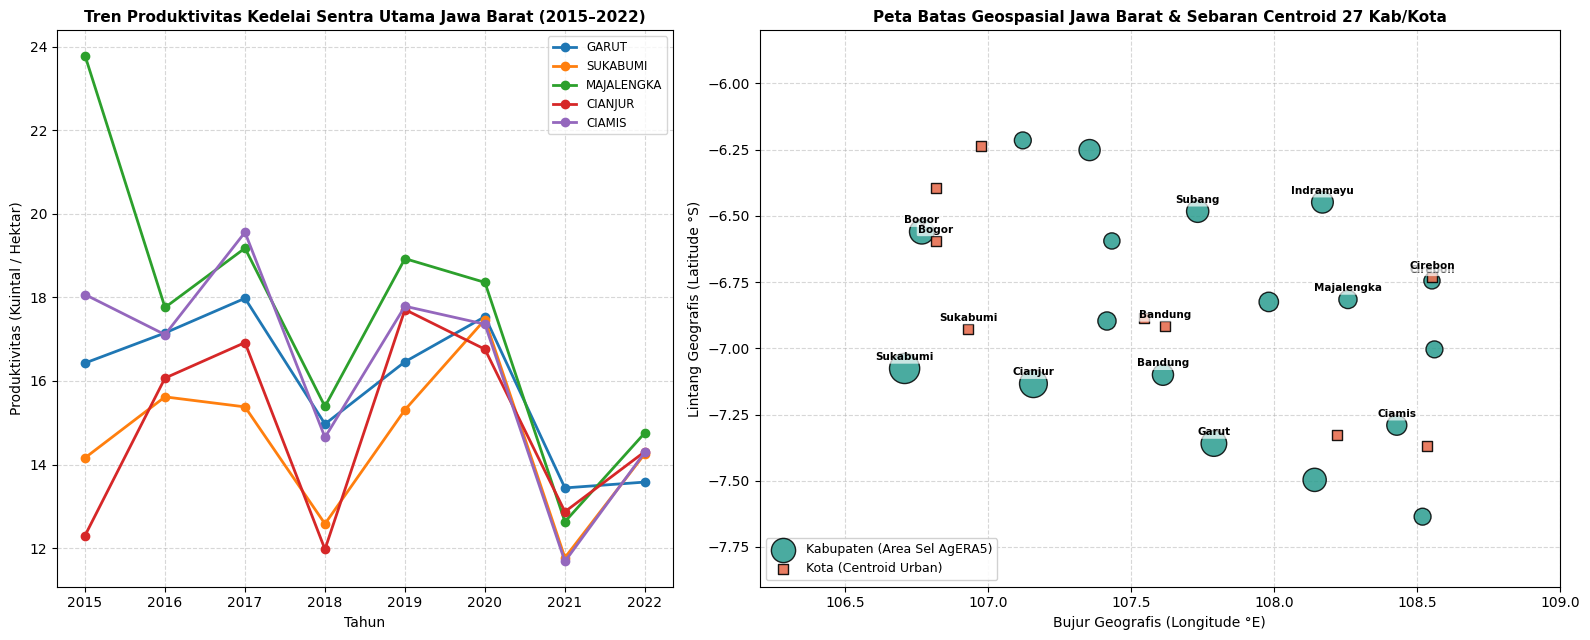

Gambar PNG diagnostik geospasial Jawa Barat berhasil disimpan ke: C:\CODING\research_taniAdapt\reports\figures\ds07_soybean_and_spatial.png


In [6]:
import geopandas as gpd

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1, 1.3]})

# Panel 1: Tren Produktivitas Kedelai Sentra Utama
top_sentra = ["KABUPATEN GARUT", "KABUPATEN SUKABUMI", "KABUPATEN MAJALENGKA", "KABUPATEN CIANJUR", "KABUPATEN CIAMIS"]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for kab, c in zip(top_sentra, colors):
    sub = df_ked[df_ked['nama_kabupaten_kota'] == kab].sort_values('tahun')
    ax1.plot(sub['tahun'], sub['produktivitas_kedelai'], marker='o', label=kab.replace('KABUPATEN ', ''), color=c, linewidth=2)

ax1.set_title("Tren Produktivitas Kedelai Sentra Utama Jawa Barat (2015–2022)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Tahun", fontsize=10)
ax1.set_ylabel("Produktivitas (Kuintal / Hektar)", fontsize=10)
ax1.legend(loc='upper right', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel 2: Peta Geospasial Berbentuk Poligon Batas Provinsi Jawa Barat + Centroid 27 Kab/Kota
path_jabar_geojson = RAW_DIR / "jawa_barat_provinsi.geojson"

if path_jabar_geojson.exists():
    gdf_jabar = gpd.read_file(path_jabar_geojson)
    gdf_jabar.plot(ax=ax2, color='#f8f9fa', edgecolor='#212529', linewidth=1.5, alpha=0.9, zorder=1)
    ax2.set_facecolor('#e9ecef') # Latar belakang laut/wilayah sekitar
else:
    ax2.grid(True, linestyle='--', alpha=0.5)

# Overlay titik-titik centroid 27 Kabupaten/Kota
if 'df_centroids' in locals() and df_centroids is not None:
    # Pisahkan Kabupaten dan Kota
    kab_pts = df_centroids[df_centroids['tipe_wilayah'] == 'KABUPATEN']
    kota_pts = df_centroids[df_centroids['tipe_wilayah'] == 'KOTA']
    
    # Plot Kabupaten dengan ukuran sebanding sel AgERA5
    sc1 = ax2.scatter(kab_pts['true_centroid_lon'], kab_pts['true_centroid_lat'], 
                      s=kab_pts['n_sel_agera5_0_1deg'] * 12 + 40, c='#2a9d8f', edgecolors='black', 
                      alpha=0.85, label='Kabupaten (Area Sel AgERA5)', zorder=3)
    
    # Plot Kota sebagai penanda oranye
    sc2 = ax2.scatter(kota_pts['true_centroid_lon'], kota_pts['true_centroid_lat'], 
                      s=50, c='#e76f51', marker='s', edgecolors='black', 
                      alpha=0.9, label='Kota (Centroid Urban)', zorder=3)
    
    # Label nama sentra utama kedelai dan wilayah besar
    key_labels = ['BANDUNG', 'GARUT', 'SUKABUMI', 'CIANJUR', 'INDRAMAYU', 'SUBANG', 'CIREBON', 'MAJALENGKA', 'CIAMIS', 'BOGOR']
    for _, row in df_centroids.iterrows():
        clean_n = row['nama_kabupaten_kota'].replace('KABUPATEN ', '').replace('KOTA ', '')
        if clean_n in key_labels:
            ax2.annotate(clean_n.title(), (row['true_centroid_lon'], row['true_centroid_lat']),
                         textcoords="offset points", xytext=(0, 6), ha='center', fontsize=7.5, fontweight='bold',
                         bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7), zorder=4)

ax2.set_title("Peta Batas Geospasial Jawa Barat & Sebaran Centroid 27 Kab/Kota", fontsize=11, fontweight='bold')
ax2.set_xlabel("Bujur Geografis (Longitude °E)", fontsize=10)
ax2.set_ylabel("Lintang Geografis (Latitude °S)", fontsize=10)
ax2.set_xlim(106.2, 109.0)
ax2.set_ylim(-7.9, -5.8)
ax2.legend(loc='lower left', framealpha=0.9, fontsize=9)

plt.tight_layout()
png_out = FIGURES_DIR / "ds07_soybean_and_spatial.png"
plt.savefig(png_out, dpi=150)
plt.show()
print(f"Gambar PNG diagnostik geospasial Jawa Barat berhasil disimpan ke: {png_out}")


## Executive Audit Scorecard — DS07 Kedelai & Batas Spasial


In [7]:
scorecard = pd.DataFrame([
    {"Dimensi Audit": "Dataset Identifier", "Hasil & Evaluasi": "DS07 — Jawa Barat Soybean Productivity & ADM2 Spatial Centroids"},
    {"Dimensi Audit": "Penerbit & Sumber", "Hasil & Evaluasi": "Distanhor Jabar (Galura API od_18105) & geoBoundaries ADM2"},
    {"Dimensi Audit": "Cakupan Spasial", "Hasil & Evaluasi": "27 Kabupaten/Kota Se-Jawa Barat (14 Sentra Tanam Penuh 8 Tahun)"},
    {"Dimensi Audit": "Rentang Periode", "Hasil & Evaluasi": "2015 s.d. 2022 (8 Tahun Observasi, N_total = 216 baris)"},
    {"Dimensi Audit": "Kelengkapan Nilai", "Hasil & Evaluasi": "PASSED (0 Missing Values, 156 observasi positif bernilai > 0 ku/ha)"},
    {"Dimensi Audit": "Satuan Resmi", "Hasil & Evaluasi": "Kuintal / Hektar"},
    {"Dimensi Audit": "Peran di TaniAdapt", "Hasil & Evaluasi": "Tier A Crop Candidate (Diuji respon iklimnya di Phase 6 EDA bersama Padi dan Jagung)"},
    {"Dimensi Audit": "Status Disposisi", "Hasil & Evaluasi": "PASS (Layak untuk analisis ekonometrika panel Two-Way Fixed Effects)"}
])
display(scorecard)


,Dimensi Audit,Hasil & Evaluasi
0,Dataset Identifier,DS07 — Jawa Barat Soybean Productivity & ADM2 ...
1,Penerbit & Sumber,Distanhor Jabar (Galura API od_18105) & geoBou...
2,Cakupan Spasial,27 Kabupaten/Kota Se-Jawa Barat (14 Sentra Tan...
3,Rentang Periode,"2015 s.d. 2022 (8 Tahun Observasi, N_total = 2..."
4,Kelengkapan Nilai,"PASSED (0 Missing Values, 156 observasi positi..."
5,Satuan Resmi,Kuintal / Hektar
6,Peran di TaniAdapt,Tier A Crop Candidate (Diuji respon iklimnya d...
7,Status Disposisi,PASS (Layak untuk analisis ekonometrika panel ...
